# Actividad — Construir un pipeline de preprocesamiento · SOLUCIONARIO
**Aprendizaje Supervisado · Unidad 2 · Preprocesamiento de datos**

**Qué haremos.** En la presentación vimos las piezas del preprocesamiento. Hoy las usarás sobre la versión original de
*California Housing* (con valores faltantes y una variable categórica) y, sobre todo, **medirás** el efecto de cada decisión:
¿qué imputación conviene? ¿importa cómo codifico? ¿qué pasa si escalo mal o si hay fuga de datos?

| Parte | Pregunta que responde | Tema de la presentación |
|---|---|---|
| 1 | ¿Cuántos datos faltan y se parecen las filas con y sin faltante? | A1–A3 |
| 2 | ¿Cómo divido sin distorsionar las proporciones? | D1–D3 |
| 3 | ¿Qué estrategia de imputación recupera mejor los valores ocultos? | A4–A9 |
| 4 | ¿Entero u *one-hot*? ¿Y si el orden sí importa? | B1–B5 |
| 5 | ¿Qué escalador conviene y para qué modelos? | C1–C6 |
| 6 | ¿Cómo se ve (y se evita) una fuga de datos? | D5–D7 |
| 7 | ¿Cómo empaqueto todo con `Pipeline` y `ColumnTransformer`? | E1–E5 |
| 8 | Tabla comparativa y resumen | Receta de siete pasos |

**Tiempo estimado:** 60–75 minutos de trabajo individual.

**Entregable:** este notebook ejecutado (con tus respuestas en las celdas ✏️) y el archivo `entregable_unidad2.csv`
con la tabla *estrategia · RMSE de validación · comentario* de la Parte 8.

**Cómo trabajar.** Ejecuta las celdas en orden. Donde dice ✏️ hay una línea de código por completar o una pregunta;
escribe tus respuestas en la celda de texto que sigue a la pregunta, bajo «**Respuesta:**».
Todas las cifras de error están en **miles de USD** (valor mediano de la vivienda ÷ 1000).

> 🔑 **Versión con respuestas (para el profesor).** Las respuestas aparecen en recuadros ✅ después de cada pregunta; las celdas de código están completas y ejecutadas. Las cifras provienen de una ejecución con `random_state` fijos; pueden variar ligeramente con otras versiones de scikit-learn.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (activa IterativeImputer)
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 140)

## Parte 0 — Los datos

Usamos la versión del libro de A. Géron (*Hands-On Machine Learning*): $n=20\,640$ distritos de California, con
`total_bedrooms` incompleta y una variable categórica, `ocean_proximity`. El archivo se descarga de GitHub la primera vez
(se necesita conexión a internet).

In [2]:
URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
try:
    df = pd.read_csv(URL)
except Exception:
    df = pd.read_csv("housing.csv")      # plan B: si descargaste el archivo y lo dejaste junto al notebook

NUM = ["longitude", "latitude", "housing_median_age", "total_rooms",
       "total_bedrooms", "population", "households", "median_income"]
CAT = ["ocean_proximity"]
OBJ = "median_house_value"
cv = KFold(5, shuffle=True, random_state=0)      # validación cruzada de 5 particiones, siempre la misma

print(df.shape)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## Parte 1 — Cuantificar los valores faltantes  *(presentación A1–A3)*

Antes de imputar o borrar hay que saber **cuántos** faltan, **dónde**, y si las filas incompletas se parecen a las completas.

In [3]:
n_falt = df.isna().sum()
pct_falt = 100 * df.isna().mean()
tabla_falt = pd.DataFrame({"faltantes": n_falt, "%": pct_falt.round(2)})
print(tabla_falt[tabla_falt["faltantes"] > 0])
print("Filas completas:", len(df.dropna()), "de", len(df))

                faltantes    %
total_bedrooms        207  1.0
Filas completas: 20433 de 20640


In [4]:
# ¿Se parecen los distritos con y sin dato en total_bedrooms?
falta = df["total_bedrooms"].isna().map({True: "sin dato", False: "con dato"})
cols = ["median_income", "median_house_value", "housing_median_age", "population"]
df.groupby(falta)[cols].mean().round(2)

,median_income,median_house_value,housing_median_age,population
total_bedrooms,,,,
con dato,3.87,206864.41,28.63,1424.95
sin dato,3.82,206007.28,29.27,1477.77


In [5]:
# ¿Hay faltantes "disfrazados"? Revisa ceros y valores imposibles en las columnas numéricas
print((df[NUM] == 0).sum().to_string())
print()
print(df[NUM].describe().loc[["min", "max"]].T)

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0

                         min         max
longitude          -124.3500   -114.3100
latitude             32.5400     41.9500
housing_median_age    1.0000     52.0000
total_rooms           2.0000  39320.0000
total_bedrooms        1.0000   6445.0000
population            3.0000  35682.0000
households            1.0000   6082.0000
median_income         0.4999     15.0001


✏️ **Pregunta 1.1.** Con base en las dos tablas anteriores, ¿qué mecanismo (MCAR, MAR o MNAR) te parece más plausible para `total_bedrooms`?
¿Qué **no** puedes concluir solo con esta comparación? ¿Encontraste faltantes disfrazados?

> ✅ **Respuesta (solucionario)**
>
> **Mecanismo:** el más plausible es **MCAR** (o cercano). Los distritos sin `total_bedrooms` tienen ingreso medio 3.82 contra 3.87, valor medio de vivienda \$206 007 contra \$206 864, edad 29.3 contra 28.6 y población 1 478 contra 1 425: son casi idénticos a los completos. Además faltan solo 207 filas (1 %).
>
> **Lo que no se puede concluir:** que sea MCAR con certeza. Comparar medias de unas pocas variables no descarta MAR (dependencia de alguna variable que no comparamos) y, sobre todo, **MNAR no se puede detectar con los datos observados**: depende del propio valor que falta, que no tenemos. Solo apoyamos la hipótesis con el conocimiento del proceso de captura.
>
> **Faltantes disfrazados:** no hay ceros ni valores imposibles en las columnas numéricas (mínimos: edad 1, habitaciones 2, ingreso 0.4999). Sí hay **topes** que ya vimos en la Unidad 1 (edad máxima 52, ingreso máximo 15.0001), que no son faltantes pero conviene recordar.

## Parte 2 — Dividir **primero**, de forma estratificada  *(presentación D1–D3)*

Regla de la receta: lo primero es separar el conjunto de prueba. Como el ingreso mediano es la variable que más
explica el precio, queremos que la **distribución del ingreso** sea la misma en entrenamiento y en prueba.
Creamos una variable auxiliar `income_cat` (5 categorías de ingreso) solo para **estratificar**.

In [6]:
df["income_cat"] = pd.cut(df["median_income"], bins=[0, 1.5, 3.0, 4.5, 6.0, np.inf], labels=[1, 2, 3, 4, 5])

train, test = train_test_split(df, test_size=0.2, stratify=df["income_cat"], random_state=42)

prop = pd.DataFrame({
    "total": df["income_cat"].value_counts(normalize=True),
    "entrenamiento": train["income_cat"].value_counts(normalize=True),
    "prueba": test["income_cat"].value_counts(normalize=True),
}).sort_index().mul(100).round(1)
print(prop)
print("\nTamaños:", len(train), "entrenamiento |", len(test), "prueba")

            total  entrenamiento  prueba
income_cat                              
1             4.0            4.0     4.0
2            31.9           31.9    31.9
3            35.1           35.1    35.1
4            17.6           17.6    17.6
5            11.4           11.4    11.4

Tamaños: 16512 entrenamiento | 4128 prueba


In [7]:
# Separamos atributos y objetivo (en miles de USD) y quitamos la variable auxiliar
X_train, y_train = train.drop(columns=[OBJ, "income_cat"]), train[OBJ] / 1000
X_test,  y_test  = test.drop(columns=[OBJ, "income_cat"]),  test[OBJ] / 1000
# A partir de aquí, el conjunto de prueba NO se toca hasta el final de la Parte 7/8.
X_train.shape, X_test.shape

((16512, 9), (4128, 9))

✏️ **Pregunta 2.1.** Compara las columnas *total*, *entrenamiento* y *prueba* de la tabla de proporciones.
¿Por qué estratificamos por el ingreso y no por, por ejemplo, `population`? ¿Qué podría pasar con una división aleatoria simple?

> ✅ **Respuesta (solucionario)**
>
> Las tres columnas coinciden (4.0 / 31.9 / 35.1 / 17.6 / 11.4 %): la estratificación conserva la distribución del ingreso en ambos conjuntos.
>
> Estratificamos por el **ingreso** porque es el predictor más fuerte del precio (correlación ≈ 0.69, Unidad 1): si la prueba tuviera un ingreso distinto al del entrenamiento, el error medido no representaría a la población. `population` no se estratifica porque no es el predictor principal y tiene una cola larguísima (de 3 a 35 682), así que no hay buenas categorías.
>
> Con una división aleatoria simple las proporciones se desvían por azar: en 200 divisiones, la categoría de ingreso más desviada se alejó en promedio 0.8 puntos porcentuales del total y hasta 2.1 puntos (por ejemplo, 16.7 % en lugar de 17.6 % en la categoría 4 con `random_state=42`). No es dramático aquí, pero con clases raras (la diapositiva D3: 8.6 % de casos «caros») puede ser mucho peor.

## Parte 3 — ¿Qué imputación recupera mejor los valores? *(presentación A4–A9)*

Para comparar estrategias necesitamos conocer la **verdad**. Tomamos las filas de entrenamiento donde `total_bedrooms` sí
existe, **ocultamos el 20 %** al azar, imputamos y medimos el error contra el valor real.

In [8]:
base = X_train[NUM].dropna(subset=["total_bedrooms"]).reset_index(drop=True)
rng = np.random.default_rng(5)
oculto = rng.random(len(base)) < 0.20                       # True = valor que ocultamos
verdad = base.loc[oculto, "total_bedrooms"].values
X_mask = base.copy()
X_mask.loc[oculto, "total_bedrooms"] = np.nan
j = NUM.index("total_bedrooms")
print(f"Ocultamos {oculto.sum()} de {len(base)} valores")

imputaciones = {}
imputaciones["media"] = SimpleImputer(strategy="mean").fit_transform(X_mask)[oculto, j]
imputaciones["mediana"] = SimpleImputer(strategy="median").fit_transform(X_mask)[oculto, j]

# KNN usa distancias: lo probamos sin escalar y con las variables estandarizadas
imputaciones["KNN (sin escalar)"] = KNNImputer(n_neighbors=5).fit_transform(X_mask)[oculto, j]
esc = StandardScaler().fit(X_mask)
X_knn = KNNImputer(n_neighbors=5).fit_transform(esc.transform(X_mask))
imputaciones["KNN (escalado)"] = esc.inverse_transform(X_knn)[oculto, j]
# Imputación iterativa (tipo MICE)
imputaciones["Iterativa (MICE)"] = IterativeImputer(max_iter=10, random_state=0).fit_transform(X_mask)[oculto, j]

Ocultamos 3313 de 16354 valores


                         RMSE  desv. est.  corr. con households
método                                                         
verdad (sin ocultar)    0.000     412.666                 0.980
media                 397.445     371.883                 0.883
mediana               407.344     374.154                 0.879
KNN (sin escalar)      74.269     409.478                 0.980
KNN (escalado)         64.317     408.732                 0.980
Iterativa (MICE)       67.284     411.746                 0.982


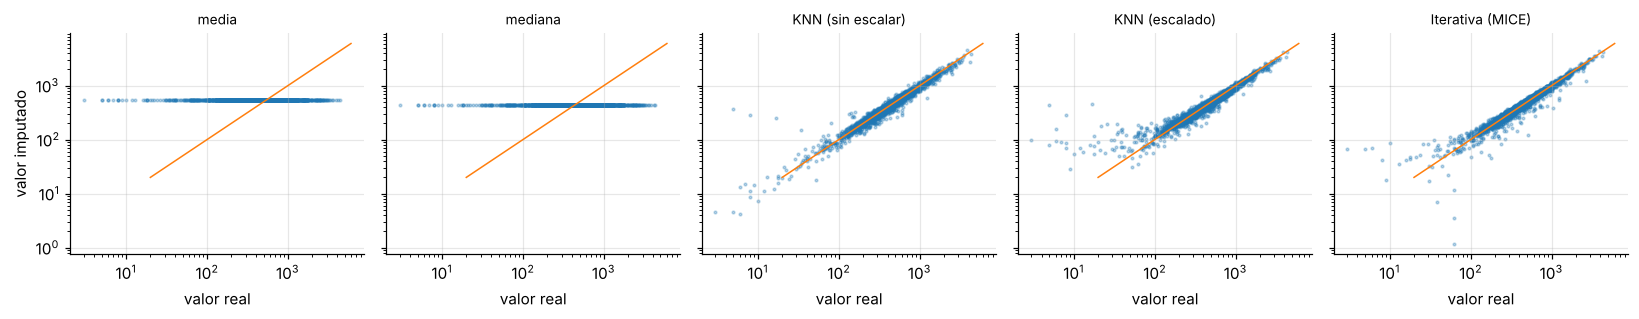

In [9]:
filas = [{"método": "verdad (sin ocultar)", "RMSE": 0.0,
          "desv. est.": base["total_bedrooms"].std(), "corr. con households": base["total_bedrooms"].corr(base["households"])}]
for nombre, vals in imputaciones.items():
    col = base["total_bedrooms"].copy()
    col[oculto] = vals                                      # columna completa tras imputar
    filas.append({"método": nombre,
                  "RMSE": float(np.sqrt(np.mean((vals - verdad) ** 2))),
                  "desv. est.": col.std(),
                  "corr. con households": col.corr(base["households"])})
tabla_imp = pd.DataFrame(filas).set_index("método").round(3)
print(tabla_imp)

fig, ax = plt.subplots(1, 5, figsize=(15, 3), sharex=True, sharey=True)
for a, (nombre, vals) in zip(ax, imputaciones.items()):
    a.scatter(verdad, vals, s=3, alpha=0.3)
    a.plot([20, 6000], [20, 6000], color="C1", lw=1)
    a.set_xscale("log"); a.set_yscale("log"); a.set_title(nombre, fontsize=9); a.set_xlabel("valor real")
ax[0].set_ylabel("valor imputado")
plt.tight_layout(); plt.show()

✏️ **Pregunta 3.1.** (a) Para media y mediana, ¿por qué el RMSE es tan parecido a la desviación estándar de la variable
y qué se ve en las gráficas? (b) ¿Qué le pasa a la desviación estándar y a la correlación con `households` al imputar con la media?
(c) ¿Qué cambia entre *KNN sin escalar* y *KNN escalado*, y por qué?

> ✅ **Respuesta (solucionario)**
>
> **(a)** Media y mediana asignan **el mismo número a todos** los valores ocultos, sin importar el distrito. Un predictor constante tiene como error típico la propia dispersión de los datos, por eso el RMSE (397 y 407) es casi la desviación estándar de la variable (413). En las gráficas todos los puntos forman una **línea horizontal**.
>
> **(b)** Aparece un pico en el valor imputado y la **desviación estándar baja** de 413 a 372. La correlación con `households` cae de **0.980 a 0.883**, aunque la relación real no cambió: los valores imputados no dependen de `households`, y diluyen la relación.
>
> **(c)** KNN usa distancias entre filas. **Sin escalar**, variables como `population` y `total_rooms` (miles) dominan la distancia sobre `median_income` o `latitude`, y los «vecinos» no son realmente parecidos: RMSE 74. Con las variables **estandarizadas**, todas pesan parecido y el RMSE baja a 64 (≈ 13 % menos). KNN e iterativa (67) conservan la desviación estándar (409–412) y la correlación (0.980–0.982): imputan usando las otras columnas.

✏️ **Pregunta 3.2.** Una tienda de crédito guarda `ingreso` solo para quienes lo declaran, y los que más ganan casi nunca lo declaran.
¿Qué mecanismo es? ¿Resolvería el problema una imputación con KNN? ¿Qué agregarías al modelo?

> ✅ **Respuesta (solucionario)**
>
> Es **MNAR**: la probabilidad de que el ingreso falte depende del propio ingreso (los que más ganan no lo declaran).
>
> **KNN no lo resuelve**: busca vecinos con *otras* variables que sí están observadas, y esos vecinos tienen, en promedio, ingresos más bajos que los de quienes no declaran, pues la información sobre «ganar mucho» justo es la que falta. La imputación seguirá subestimando el ingreso.
>
> Lo que se puede hacer: (1) agregar un **indicador de faltante** (`add_indicator=True`), porque *no declarar* es en sí informativo del ingreso alto; (2) buscar una fuente externa o una variable proxy (ocupación, tipo de vivienda); (3) analizar la sensibilidad de las conclusiones a distintos supuestos; (4) documentar claramente la limitación.

## Parte 4 — Codificar `ocean_proximity` *(presentación B1–B5)*

Comparamos dos formas de convertir la categoría en números, ajustando los codificadores **solo con el entrenamiento**
y usando una regresión lineal con esa única variable.

In [10]:
print(X_train["ocean_proximity"].value_counts().to_string())
print("\nEn prueba:\n" + X_test["ocean_proximity"].value_counts().to_string())

ocean_proximity
<1H OCEAN     7277
INLAND        5262
NEAR OCEAN    2124
NEAR BAY      1847
ISLAND           2

En prueba:
ocean_proximity
<1H OCEAN     1859
INLAND        1289
NEAR OCEAN     534
NEAR BAY       443
ISLAND           3


In [11]:
cat_train, cat_test = X_train[CAT], X_test[CAT]

ord_enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(cat_train)   # códigos 0,1,2,... (alfabético)
oh_enc = OneHotEncoder(handle_unknown="ignore").fit(cat_train)

print("Códigos enteros:", dict(zip(ord_enc.categories_[0], range(len(ord_enc.categories_[0])))))
print("Columnas one-hot:", list(oh_enc.get_feature_names_out()))

for nombre, enc in [("entero", ord_enc), ("one-hot", oh_enc)]:
    A_tr, A_te = enc.transform(cat_train), enc.transform(cat_test)
    lr = LinearRegression().fit(A_tr, y_train)
    print(f"{nombre:8s} R² entrenamiento = {lr.score(A_tr, y_train):.3f}   R² prueba = {lr.score(A_te, y_test):.3f}")

Códigos enteros: {'<1H OCEAN': 0, 'INLAND': 1, 'ISLAND': 2, 'NEAR BAY': 3, 'NEAR OCEAN': 4}
Columnas one-hot: ['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']
entero   R² entrenamiento = 0.006   R² prueba = 0.010
one-hot  R² entrenamiento = 0.236   R² prueba = 0.248


In [12]:
# Cuando el orden SÍ existe: tallas S < M < L
tallas = pd.DataFrame({"talla": ["M", "S", "L", "M", "S"]})
enc = OrdinalEncoder(categories=[["S", "M", "L"]])
tallas["código"] = enc.fit_transform(tallas[["talla"]])
tallas

,talla,código
0,M,1.0
1,S,0.0
2,L,2.0
3,M,1.0
4,S,0.0


✏️ **Pregunta 4.1.** (a) ¿Por qué el código entero ajusta tan mal y el *one-hot* mucho mejor? (b) ¿Qué ocurriría si
`ISLAND` aparece en prueba pero no en entrenamiento, y qué hace `handle_unknown="ignore"`? (c) ¿Qué códigos asignó `OrdinalEncoder` por defecto a las tallas y por qué eso es un error?

> ✅ **Respuesta (solucionario)**
>
> **(a)** El código entero (alfabético: `<1H OCEAN`=0, `INLAND`=1, `ISLAND`=2, `NEAR BAY`=3, `NEAR OCEAN`=4) obliga al modelo lineal a ajustar **una recta** sobre un orden que no tiene significado: `INLAND` (barato) queda entre dos categorías caras y la recta casi no explica nada (R² ≈ 0.006 en entrenamiento y 0.010 en prueba). Con *one-hot* cada categoría tiene su propio coeficiente (su promedio) y R² sube a 0.236 en entrenamiento y 0.248 en prueba. Sin orden real, el entero inventa distancias.
>
> **(b)** `ISLAND` es rarísima (2 distritos en entrenamiento, 3 en prueba). Si una categoría aparece en prueba y no en entrenamiento, `OneHotEncoder` por defecto lanza un **error**; con `handle_unknown="ignore"` esa fila recibe ceros en todas las columnas y el modelo sigue funcionando (la trata como «ninguna categoría conocida»).
>
> **(c)** Por defecto asigna códigos **alfabéticos**: `L`=0, `M`=1, `S`=2, es decir, el orden contrario al real (S<M<L). Un modelo creería que `L` es la talla más pequeña. Se corrige con `categories=[["S", "M", "L"]]`.

## Parte 5 — Escalar: ¿cuál y para qué modelo? *(presentación C1–C6)*

Primero verifica la regla **fit con entrenamiento, transform con todos**; después compara cuatro opciones de escalado con dos modelos.

In [13]:
imp = SimpleImputer(strategy="median").fit(X_train[NUM])
Xtr, Xte = imp.transform(X_train[NUM]), imp.transform(X_test[NUM])

sc = StandardScaler().fit(Xtr)            # aprende μ y σ SOLO del entrenamiento
Ztr, Zte = sc.transform(Xtr), sc.transform(Xte)

print(pd.DataFrame({"media entren.": Ztr.mean(0), "desv. entren.": Ztr.std(0),
                    "media prueba": Zte.mean(0), "desv. prueba": Zte.std(0)}, index=NUM).round(3))

                    media entren.  desv. entren.  media prueba  desv. prueba
longitude                     0.0            1.0         0.015         1.004
latitude                      0.0            1.0        -0.017         0.995
housing_median_age            0.0            1.0        -0.006         1.004
total_rooms                  -0.0            1.0         0.031         1.097
total_bedrooms               -0.0            1.0         0.035         1.100
population                   -0.0            1.0         0.026         1.073
households                   -0.0            1.0         0.034         1.085
median_income                -0.0            1.0        -0.014         0.986


In [14]:
def cv_rmse(modelo, Xd, yd):
    s = -cross_val_score(modelo, Xd, yd, cv=cv, scoring="neg_root_mean_squared_error")
    return s.mean(), s.std()

escaladores = {"sin escalar": "passthrough", "StandardScaler": StandardScaler(),
               "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}
modelos = {"KNN (k=10)": KNeighborsRegressor(n_neighbors=10),
           "Árbol (prof. 8)": DecisionTreeRegressor(max_depth=8, random_state=0)}

filas = []
for nom_esc, escalador in escaladores.items():
    for nom_mod, modelo in modelos.items():
        pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", escalador), ("mod", modelo)])
        m, s = cv_rmse(pipe, X_train[NUM], y_train)
        filas.append({"escalador": nom_esc, "modelo": nom_mod, "RMSE validación": round(m, 2), "± desv": round(s, 2)})

tabla_esc = pd.DataFrame(filas).pivot(index="escalador", columns="modelo", values="RMSE validación")
tabla_esc.loc[list(escaladores)]

modelo,KNN (k=10),Árbol (prof. 8)
escalador,,
sin escalar,96.63,66.86
StandardScaler,62.59,66.87
MinMaxScaler,63.44,66.84
RobustScaler,64.02,66.88


✏️ **Pregunta 5.1.** (a) En la primera tabla, ¿las medias y desviaciones de **prueba** son exactamente 0 y 1? ¿Por qué no, y por qué eso es correcto?
(b) En la segunda tabla, ¿qué modelo se beneficia de escalar y cuál no? (c) ¿Diferencias entre los tres escaladores en este conjunto? ¿Cuándo preferirías `RobustScaler`?

> ✅ **Respuesta (solucionario)**
>
> **(a)** En entrenamiento las medias son 0 y las desviaciones 1 por construcción. En **prueba** no: salen medias entre −0.02 y 0.04 y desviaciones entre 0.99 y 1.10. Es lo correcto: transformamos la prueba con la media y la desviación **del entrenamiento**, como lo haríamos con datos nuevos reales. Si re-ajustáramos con la prueba habría fuga y no sabríamos qué tan bien funciona con datos que no conocemos.
>
> **(b)** **KNN** se beneficia muchísimo: RMSE de 96.6 (sin escalar) a 62.6 (StandardScaler). El **árbol** no cambia (66.9 en los cuatro casos): solo compara umbrales dentro de cada variable, y escalar no altera el orden.
>
> **(c)** Entre los tres escaladores la diferencia es pequeña (62.6, 63.4 y 64.0): en estos datos no hay atípicos que dominen. Preferiríamos `RobustScaler` con **atípicos o colas pesadas** (usa mediana y cuartiles, que casi no se mueven), `MinMaxScaler` cuando se necesita un rango fijo [0, 1] (imágenes, redes neuronales) y sin atípicos, y `StandardScaler` como opción por defecto.

## Parte 6 — Provocar y medir una fuga de datos *(presentación D5–D7)*

Datos de **puro ruido**: 100 filas, 2 000 atributos al azar y una etiqueta 0/1 al azar. No hay nada que aprender, así que
la exactitud correcta es ≈ 0.50. Repetimos 10 veces dos procedimientos:

* **Con fuga:** elegir los 20 atributos «más relacionados» con la etiqueta usando *todos* los datos, y *después* validar.
* **Sin fuga:** hacer esa selección *dentro* de cada partición, con un `Pipeline`.

Con fuga:  exactitud media = 0.85
Sin fuga:  exactitud media = 0.52   (azar = 0.50)


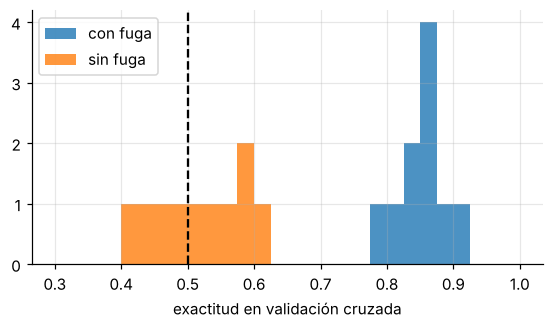

In [15]:
rng = np.random.default_rng(0)
con_fuga, sin_fuga = [], []
for rep in range(10):
    Xr = rng.normal(size=(100, 2000))
    yr = rng.integers(0, 2, 100)

    # CON FUGA: la selección ya "vio" todas las etiquetas
    Xsel = SelectKBest(f_classif, k=20).fit_transform(Xr, yr)
    con_fuga.append(cross_val_score(LogisticRegression(max_iter=500), Xsel, yr, cv=5).mean())

    pipe_ok = Pipeline([("sel", SelectKBest(f_classif, k=20)), ("lr", LogisticRegression(max_iter=500))])
    sin_fuga.append(cross_val_score(pipe_ok, Xr, yr, cv=5).mean())

print(f"Con fuga:  exactitud media = {np.mean(con_fuga):.2f}")
print(f"Sin fuga:  exactitud media = {np.mean(sin_fuga):.2f}   (azar = 0.50)")
plt.figure(figsize=(6, 3))
plt.hist(con_fuga, bins=np.linspace(0.3, 1, 29), alpha=0.8, label="con fuga")
plt.hist(sin_fuga, bins=np.linspace(0.3, 1, 29), alpha=0.8, label="sin fuga")
plt.axvline(0.5, color="k", ls="--"); plt.xlabel("exactitud en validación cruzada"); plt.legend(); plt.show()

✏️ **Pregunta 6.1.** (a) ¿Por qué el procedimiento con fuga «encuentra» un patrón que no existe? (b) En la Parte 5, escalar antes de dividir
sí es una fuga, pero casi no cambiaría los resultados; aquí la selección sí los cambia enormemente. ¿Por qué la diferencia?
(c) Nombra otra fuga posible en un problema de crédito (pista: la tabla D5 de la presentación).

> ✅ **Respuesta (solucionario)**
>
> **(a)** Con 2 000 atributos aleatorios, algunos se correlacionan con la etiqueta *por casualidad* en esas 100 filas. Elegir los 20 «mejores» mirando **todas** las etiquetas selecciona justo esa casualidad; luego, al validar, esos atributos ya «conocen» las etiquetas de los pliegues de validación, y la exactitud sube a ≈ 0.85. Dentro de cada partición, la selección solo ve el entrenamiento y la exactitud vuelve a ≈ 0.52 (azar), que es la respuesta correcta.
>
> **(b)** Escalar antes de dividir filtra solo **dos números por columna** (media y desviación estándar), sin usar la etiqueta `y`; el efecto es mínimo. La selección de atributos **usa la etiqueta**, y con muchísimos candidatos (2 000 contra 100 filas) se ajusta a ruido: filtra información del objetivo y con enorme efecto. La gravedad de una fuga depende de *cuánta* información del objetivo se filtra.
>
> **(c)** Por ejemplo, una columna como «días de atraso» o «cuenta enviada a cobranza» que solo existe *después* de saber si el cliente pagó (fuga del objetivo), o mezclar solicitudes de la misma persona entre entrenamiento y prueba (duplicados), o validar con un corte aleatorio cuando el modelo se usará a futuro (fuga temporal).

## Parte 7 — El pipeline completo *(presentación E1–E5)*

Empaquetamos imputación, escalado y codificación en un solo objeto. Después lo validamos con validación cruzada
y buscamos hiperparámetros del modelo **y** del preprocesamiento.

> Tus cifras serán parecidas, no idénticas, a las del código de la diapositiva E4: allí la división de datos no estaba estratificada.

In [16]:
num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
prep = ColumnTransformer([("num", num_pipe, NUM), ("cat", cat_pipe, CAT)])

modelo = Pipeline([("prep", prep), ("knn", KNeighborsRegressor(n_neighbors=10))])

# ¿Cuántas columnas produce el preprocesador? (debería ser 13: 8 numéricas + 5 one-hot)
print("Columnas tras preprocesar:", modelo[:-1].fit(X_train, y_train).transform(X_train).shape[1])
print(list(prep.get_feature_names_out()))

m, s = cv_rmse(modelo, X_train, y_train)
print(f"\nRMSE de validación cruzada: {m:.2f} ± {s:.2f}  (miles de USD)")

Columnas tras preprocesar: 13
['num__longitude', 'num__latitude', 'num__housing_median_age', 'num__total_rooms', 'num__total_bedrooms', 'num__population', 'num__households', 'num__median_income', 'cat__ocean_proximity_<1H OCEAN', 'cat__ocean_proximity_INLAND', 'cat__ocean_proximity_ISLAND', 'cat__ocean_proximity_NEAR BAY', 'cat__ocean_proximity_NEAR OCEAN']



RMSE de validación cruzada: 61.20 ± 0.86  (miles de USD)


In [17]:
param_grid = {
    "knn__n_neighbors": [5, 10, 20],
    "prep__num__imputer__strategy": ["mean", "median"],
}
busqueda = GridSearchCV(modelo, param_grid, cv=cv, scoring="neg_root_mean_squared_error")
busqueda.fit(X_train, y_train)

print("Mejores parámetros:", busqueda.best_params_)
print(f"RMSE de validación (mejor combinación): {-busqueda.best_score_:.2f}")
pd.DataFrame(busqueda.cv_results_)[["params", "mean_test_score"]].assign(RMSE=lambda d: -d["mean_test_score"]).drop(columns="mean_test_score").round(2)

Mejores parámetros: {'knn__n_neighbors': 10, 'prep__num__imputer__strategy': 'median'}
RMSE de validación (mejor combinación): 61.20


,params,RMSE
0,"{'knn__n_neighbors': 5, 'prep__num__imputer__s...",62.00
1,"{'knn__n_neighbors': 5, 'prep__num__imputer__s...",61.98
2,"{'knn__n_neighbors': 10, 'prep__num__imputer__...",61.20
3,"{'knn__n_neighbors': 10, 'prep__num__imputer__...",61.20
4,"{'knn__n_neighbors': 20, 'prep__num__imputer__...",61.52
5,"{'knn__n_neighbors': 20, 'prep__num__imputer__...",61.52


In [18]:
# Ahora sí: el conjunto de prueba se usa UNA sola vez, con el mejor modelo ya elegido
final = busqueda.best_estimator_
pred = final.predict(X_test)
rmse_prueba = float(np.sqrt(mean_squared_error(y_test, pred)))
print(f"RMSE en prueba: {rmse_prueba:.2f}   R² en prueba: {r2_score(y_test, pred):.3f}")

RMSE en prueba: 58.88   R² en prueba: 0.734


✏️ **Pregunta 7.1.** (a) ¿Qué significa el nombre `prep__num__imputer__strategy`? (b) ¿Por qué la búsqueda con `GridSearchCV` sobre un `Pipeline` **no** tiene fuga?
(c) Si en vez del pipeline hubieras hecho `StandardScaler().fit_transform(X)` sobre todo el conjunto y luego `GridSearchCV`, ¿qué habría salido mal?

> ✅ **Respuesta (solucionario)**
>
> **(a)** Es el camino para llegar al parámetro, separado por doble guion bajo: del paso `prep` (el `ColumnTransformer`) → rama `num` (`num_pipe`) → paso `imputer` (el `SimpleImputer`) → parámetro `strategy`. Es decir, cambia la estrategia de imputación de las variables numéricas.
>
> **(b)** En cada partición de la validación cruzada, `GridSearchCV` **vuelve a ajustar todo el pipeline** (medianas, μ, σ, categorías del one-hot, modelo) solo con el pedazo de entrenamiento y evalúa en el pedazo de validación. Nada se calcula con las filas de validación.
>
> **(c)** Habríamos calculado μ y σ con *todas* las filas, incluidas las que luego servirían de validación (y de prueba), antes de la búsqueda. Cada pliegue de validación «influyó» en el escalado: fuga. Aquí el efecto sería pequeño (dos números por columna), pero la costumbre es peligrosa: con selección de atributos, imputación basada en vecinos o *target encoding* sería grave.

## Parte 8 — Tabla comparativa y resumen *(entregable)*

Compara estrategias completas de preprocesamiento con el **mismo modelo** (KNN, $k=10$) y la **misma validación cruzada**
sobre el conjunto de entrenamiento. Es el experimento de la segunda diapositiva de la presentación, ahora con tu propio código.

In [19]:
resultados, pipes = [], {}

def evalua(nombre, pipe, Xd=None, yd=None):
    Xd = X_train if Xd is None else Xd
    yd = y_train if yd is None else yd
    m, s = cv_rmse(pipe, Xd, yd)
    resultados.append({"estrategia": nombre, "RMSE validación": round(m, 2), "± desv": round(s, 2), "comentario": ""})
    pipes[nombre] = pipe
    print(f"{nombre:55s} {m:6.2f} ± {s:4.2f}")

def crea_prep(imp_num, esc):
    # preprocesador completo: numéricas (imputar + escalar) y categórica (moda + one-hot)
    return ColumnTransformer([
        ("num", make_pipeline(imp_num, esc), NUM),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), CAT)])

knn = lambda: KNeighborsRegressor(n_neighbors=10)
completas = X_train.dropna().index

evalua("1. Borrar filas incompletas, sin escalar", Pipeline([("knn", knn())]), X_train.loc[completas, NUM], y_train.loc[completas])
evalua("2. Imputar con mediana, sin escalar", make_pipeline(SimpleImputer(strategy="median"), knn()), X_train[NUM])
evalua("3. + estandarizar", make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), knn()), X_train[NUM])
evalua("4. + one-hot de ocean_proximity",
       Pipeline([("prep", crea_prep(SimpleImputer(strategy="median"), StandardScaler())), ("knn", knn())]))
evalua("5. Como 4, pero con RobustScaler",
       Pipeline([("prep", crea_prep(SimpleImputer(strategy="median"), RobustScaler())), ("knn", knn())]))
evalua("6. Como 4, pero imputando con KNNImputer",
       Pipeline([("prep", crea_prep(KNNImputer(n_neighbors=5), StandardScaler())), ("knn", knn())]))
evalua("7. Como 4, con indicador de faltante",
       Pipeline([("prep", crea_prep(SimpleImputer(strategy="median", add_indicator=True), StandardScaler())), ("knn", knn())]))

1. Borrar filas incompletas, sin escalar                 96.78 ± 0.91


2. Imputar con mediana, sin escalar                      96.63 ± 0.42


3. + estandarizar                                        62.59 ± 1.44


4. + one-hot de ocean_proximity                          61.20 ± 0.86


5. Como 4, pero con RobustScaler                         61.29 ± 1.02


6. Como 4, pero imputando con KNNImputer                 61.14 ± 0.84


7. Como 4, con indicador de faltante                     61.40 ± 0.94


In [20]:
tabla_final = pd.DataFrame(resultados)
COMENT = {0: 'Borrar solo 207 filas casi no cambia el error, pero sin escalar el KNN está dominado por total_rooms y population.', 1: 'Imputar con la mediana conserva todas las filas y da lo mismo (96.6): con 1 % de faltantes no es lo importante.', 2: 'Estandarizar es la mejora grande: de 96.6 a 62.6 (el modelo usa distancias).', 3: 'El one-hot de ocean_proximity baja a 61.2 y reduce la desviación entre particiones.', 4: 'RobustScaler (61.3) equivale a StandardScaler: no hay atípicos que dominen; no justifica cambiarlo.', 5: 'La imputación con KNN (61.1) es la mejor numéricamente, pero la diferencia (0.06) es menor que la desviación entre particiones: empate técnico.', 6: 'El indicador de faltante no ayuda (61.4): con faltantes casi MCAR, faltar no informa.'}
for i, txt in COMENT.items():
    tabla_final.loc[i, "comentario"] = txt
tabla_final

,estrategia,RMSE validación,± desv,comentario
0,"1. Borrar filas incompletas, sin escalar",96.78,0.91,"Borrar solo 207 filas casi no cambia el error,..."
1,"2. Imputar con mediana, sin escalar",96.63,0.42,Imputar con la mediana conserva todas las fila...
2,3. + estandarizar,62.59,1.44,Estandarizar es la mejora grande: de 96.6 a 62...
3,4. + one-hot de ocean_proximity,61.20,0.86,El one-hot de ocean_proximity baja a 61.2 y re...
4,"5. Como 4, pero con RobustScaler",61.29,1.02,RobustScaler (61.3) equivale a StandardScaler:...
5,"6. Como 4, pero imputando con KNNImputer",61.14,0.84,La imputación con KNN (61.1) es la mejor numér...
6,"7. Como 4, con indicador de faltante",61.40,0.94,El indicador de faltante no ayuda (61.4): con ...


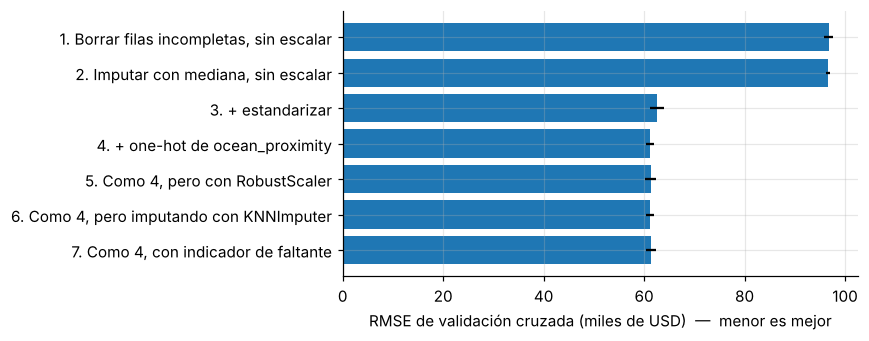

Guardado: entregable_unidad2.csv


In [21]:
plt.figure(figsize=(8, 3.2))
plt.barh(tabla_final["estrategia"][::-1], tabla_final["RMSE validación"][::-1], xerr=tabla_final["± desv"][::-1], color="C0")
plt.xlabel("RMSE de validación cruzada (miles de USD)  —  menor es mejor"); plt.tight_layout(); plt.show()

# Guarda la tabla para entregarla junto con el notebook
tabla_final.to_csv("entregable_unidad2.csv", index=False, encoding="utf-8")
print("Guardado: entregable_unidad2.csv")

In [22]:
# Mejor estrategia por validación → ajuste con TODO el entrenamiento → UNA evaluación en prueba
mejor = tabla_final.loc[tabla_final.index[1:].map(lambda i: tabla_final.loc[i, "RMSE validación"]).argmin() + 1, "estrategia"]
pipe_mejor = pipes[mejor]
pipe_mejor.fit(X_train, y_train)
pred = pipe_mejor.predict(X_test)
print(mejor)
print(f"RMSE en prueba: {np.sqrt(mean_squared_error(y_test, pred)):.2f}   R² en prueba: {r2_score(y_test, pred):.3f}")

6. Como 4, pero imputando con KNNImputer
RMSE en prueba: 58.85   R² en prueba: 0.734


### Reflexión final (3–5 líneas)

1. De todas las decisiones de preprocesamiento que probaste, ¿cuál cambió **más** el error y cuál casi nada? Relaciónalo con lo que pasa con los datos (escala, faltantes, categoría).
2. ¿Qué parte de este flujo habría tenido fuga si no hubieras usado `Pipeline`? ¿Y si hubieras escogido hiperparámetros mirando el conjunto de prueba?
3. Escribe tu **receta personal** (3 pasos) para empezar cualquier problema con datos tabulares nuevos.

> ✅ **Respuesta (solucionario)**
>
> Respuesta modelo (puede variar):
>
> 1. **Escalar** cambió más el error (de ≈ 96.6 a 62.6 con KNN); codificar `ocean_proximity` lo bajó un poco más (61.2); imputar con una u otra técnica, borrar filas o cambiar de escalador casi no cambió nada (61.1–61.4, dentro de ±1 desviación entre particiones). Razón: KNN depende de las distancias y las escalas distintas dominaban; en cambio solo falta el 1 % de una columna.
> 2. Sin `Pipeline`, habría tenido fuga el imputador, el escalador y el codificador si se hubieran ajustado con todo el conjunto antes de la validación cruzada. Elegir hiperparámetros mirando la prueba convierte la prueba en validación: el error reportado sería optimista.
> 3. Receta: (i) dividir primero (estratificado si hace falta) y no tocar la prueba; (ii) explorar el entrenamiento: faltantes, tipos, atípicos; (iii) empaquetar el preprocesamiento en `ColumnTransformer` + `Pipeline`, validar con validación cruzada y evaluar en prueba **una vez**.

---
### Reto opcional

Reemplaza `KNeighborsRegressor` por `DecisionTreeRegressor(max_depth=8)` en la estrategia 4 y compara contra las estrategias 2 y 3 (¿le importa el escalado?);
luego prueba `OneHotEncoder(handle_unknown="ignore", min_frequency=100)` y explica qué hace con `ISLAND`.

In [23]:
# Reto opcional
arbol = lambda: DecisionTreeRegressor(max_depth=8, random_state=0)
for nombre, pipe, Xd in [
    ("árbol, mediana, sin escalar", make_pipeline(SimpleImputer(strategy="median"), arbol()), X_train[NUM]),
    ("árbol, mediana + estandarizar", make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), arbol()), X_train[NUM]),
    ("árbol, preprocesador completo", Pipeline([("prep", crea_prep(SimpleImputer(strategy="median"), StandardScaler())), ("arbol", arbol())]), X_train),
]:
    m, s = cv_rmse(pipe, Xd, y_train)
    print(f"{nombre:34s} {m:6.2f} ± {s:4.2f}")

oh_raros = OneHotEncoder(handle_unknown="ignore", min_frequency=100).fit(X_train[CAT])
print("\nCategorías tras min_frequency=100:", list(oh_raros.get_feature_names_out()))

árbol, mediana, sin escalar         66.86 ± 2.29


árbol, mediana + estandarizar       66.87 ± 2.25


árbol, preprocesador completo       64.01 ± 1.60

Categorías tras min_frequency=100: ['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN', 'ocean_proximity_infrequent_sklearn']


> ✅ **Respuesta (solucionario)**
>
> **Árbol:** sin escalar 66.86, estandarizado 66.87: **el escalado no le afecta**. Con el preprocesador completo (one-hot de `ocean_proximity`) baja a 64.01: la categoría sí aporta información al árbol.
>
> **`min_frequency=100`:** las categorías con menos de 100 ejemplos se agrupan en una columna `ocean_proximity_infrequent_sklearn`. `ISLAND` (2 ejemplos en entrenamiento) deja de tener columna propia y queda agrupada; así el modelo no aprende un coeficiente a partir de solo 2 distritos.